# 03. Análisis y visualización

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv(
    "../data/processed/bank_clean.csv",
    parse_dates=["fecha_contacto", "fecha_alta"],
)
df.shape

(43000, 36)

In [3]:
# Columnas enteras con nulos: de float64 a Int64
columnas_int = ["edad", "dias_ultimo_contacto", "anio_contacto", "mes_contacto", "trimestre_contacto"]
for col in columnas_int:
    df[col] = df[col].astype("Int64")

# Categorías con orden lógico (para que las tablas y gráficos no salgan en orden alfabético)
orden_edad = ["<25", "25-34", "35-44", "45-54", "55-64", "65+", "desconocido"]
orden_ingresos = ["bajo", "medio-bajo", "medio-alto", "alto"]

df["grupo_edad"] = pd.Categorical(df["grupo_edad"], categories=orden_edad, ordered=True)
df["tramo_ingresos"] = pd.Categorical(df["tramo_ingresos"], categories=orden_ingresos, ordered=True)

In [4]:
def resumen_de_nulos(df):
    resumen = pd.DataFrame({
        "nulos": df.isnull().sum(),
        "porcentaje": (df.isnull().mean() * 100).round(1),
    })
    return resumen[resumen["nulos"] > 0].sort_values("nulos", ascending=False)

# resumen_de_nulos(df_bank)

In [5]:
df[columnas_int + ["grupo_edad", "tramo_ingresos"]].dtypes
resumen_de_nulos(df)

,nulos,porcentaje
dias_ultimo_contacto,41412,96.3
edad,5120,11.9
fecha_contacto,248,0.6
antiguedad_anios,248,0.6
anio_contacto,248,0.6
mes_contacto,248,0.6
trimestre_contacto,248,0.6


In [6]:
vars_numericas = [
    "edad", "duracion", "contactos_campana", "contactos_previos", "dias_ultimo_contacto",
    "ingresos", "visitas_web_mes", "total_hijos", "antiguedad_anios",
    "tasa_var_empleo", "indice_precios", "indice_confianza", "euribor_3m", "num_empleados",
]

vars_categoricas = [
    "trabajo", "estado_civil", "educacion", "hipoteca", "prestamo",
    "medio_contacto", "resultado_previo", "contactado_antes",
    "grupo_edad", "tramo_ingresos", "suscrito",
]

# Qué dejamos fuera y por qué:
# id_cliente: es un identificador, no se analiza.
# latitud y longitud: coordenadas de EE. UU., incoherentes con el enunciado. Ya está documentado.
# num_ninos y num_adolescentes: están recogidos en total_hijos.
# fecha_*, anio_*, mes_*, trimestre_*: se analizarán como serie temporal, no con estadísticos descriptivos.
# suscrito_num: es la versión numérica de suscrito.

In [7]:
descriptivo = df[vars_numericas].astype(float).describe().T
descriptivo["mediana"] = df[vars_numericas].astype(float).median()
descriptivo[["count", "mean", "mediana", "std", "min", "max"]].round(2)

,count,mean,mediana,std,min,max
edad,37880.0,39.98,38.00,10.44,17.00,98.00
duracion,43000.0,257.74,179.00,258.67,0.00,4918.00
contactos_campana,43000.0,2.57,2.00,2.77,1.00,56.00
contactos_previos,43000.0,0.17,0.00,0.50,0.00,7.00
dias_ultimo_contacto,1588.0,6.07,6.00,3.86,0.00,27.00
ingresos,43000.0,93241.20,93050.50,50498.32,5841.00,180802.00
visitas_web_mes,43000.0,16.59,17.00,9.24,1.00,32.00
total_hijos,43000.0,2.00,2.00,1.15,0.00,4.00
antiguedad_anios,42752.0,4.14,4.10,1.72,0.00,8.00
tasa_var_empleo,43000.0,0.08,1.10,1.57,-3.40,1.40


In [8]:
descriptivo["dif_media_mediana_%"] = ((descriptivo["mean"] - descriptivo["mediana"]) / descriptivo["mediana"] * 100).round(1)
descriptivo[["mean", "mediana", "dif_media_mediana_%"]].round(2)

,mean,mediana,dif_media_mediana_%
edad,39.98,38.00,5.2
duracion,257.74,179.00,44.0
contactos_campana,2.57,2.00,28.4
contactos_previos,0.17,0.00,inf
dias_ultimo_contacto,6.07,6.00,1.2
ingresos,93241.20,93050.50,0.2
visitas_web_mes,16.59,17.00,-2.4
total_hijos,2.00,2.00,0.2
antiguedad_anios,4.14,4.10,0.9
tasa_var_empleo,0.08,1.10,-93.0


In [9]:
descriptivo["coef_variacion_%"] = (descriptivo["std"] / descriptivo["mean"] * 100).round(1)
descriptivo[["std", "mean", "coef_variacion_%"]].round(2)

# No incluir estos resultados pues exceden el alcance del ejercicio.

,std,mean,coef_variacion_%
edad,10.44,39.98,26.1
duracion,258.67,257.74,100.4
contactos_campana,2.77,2.57,108.0
contactos_previos,0.50,0.17,285.8
dias_ultimo_contacto,3.86,6.07,63.6
ingresos,50498.32,93241.20,54.2
visitas_web_mes,9.24,16.59,55.7
total_hijos,1.15,2.00,57.6
antiguedad_anios,1.72,4.14,41.6
tasa_var_empleo,1.57,0.08,2040.6


### Interpretación de las variables numéricas
- `edad`: media X, mediana Y → distribución [simétrica / ligeramente asimétrica].
- `duracion`: media X frente a mediana Y → asimetría a la derecha (llamadas muy largas).
- `contactos_campana`: ...
- Variables económicas (`euribor_3m`, `num_empleados`...): ver nota.
- `ingresos`, `visitas_web_mes`, `total_hijos`: distribuciones muy uniformes (posible origen sintético).

Nota sobre las variables económicas: tasa_var_empleo, indice_precios, indice_confianza, euribor_3m y num_empleados no son atributos del cliente, sino del momento de la llamada. Muchas filas comparten el mismo valor (los “paquetes” de la Sesión 4), así que su media describe el periodo, no al cliente. Menciónalo en la interpretación.

In [10]:
def tabla_frecuencias(df, columna):
    frec = df[columna].value_counts(dropna=False)
    porc = (df[columna].value_counts(dropna=False, normalize=True) * 100).round(1)
    return pd.DataFrame({"frecuencia": frec, "porcentaje": porc})

In [11]:
for col in vars_categoricas:
    print(f"--- {col} ---")
    print(tabla_frecuencias(df, col))
    print()

--- trabajo ---
               frecuencia  porcentaje
trabajo                              
admin.              10873        25.3
blue-collar          9654        22.5
technician           7026        16.3
services             4162         9.7
management           3050         7.1
retired              1790         4.2
entrepreneur         1522         3.5
self-employed        1489         3.5
housemaid            1123         2.6
unemployed           1063         2.5
student               903         2.1
desconocido           345         0.8

--- estado_civil ---
              frecuencia  porcentaje
estado_civil                        
married            25999        60.5
single             12105        28.2
divorced            4811        11.2
desconocido           85         0.2

--- educacion ---
                     frecuencia  porcentaje
educacion                                  
university.degree         12722        29.6
high.school                9925        23.1
basic.9y     

### Interpretación de las variables categóricas
- Perfil dominante: ...
- Categorías minoritarias a tratar con cautela: ...
- Peso de "desconocido": ...
- Variable objetivo desbalanceada: 11,3 % de `yes`.

## Resumen de la Sesión 7
- Dataset cargado desde `bank_clean.csv` con `parse_dates` y tipos restaurados.
- Estadísticos de 14 variables numéricas (media, mediana, desviación, mín., máx.).
- Frecuencias de 11 variables categóricas con la función `tabla_frecuencias`.
- Interpretaciones escritas.

# Interpretación de variables 

### Interpretación de las variables numéricas

**Variables del cliente y de la llamada**
- `edad`: media 40,0 y mediana 38 años (diferencia del 5,2 %). Distribución ligeramente asimétrica hacia edades altas, con máximo de 98. El 11,9 % de las filas no tiene edad. Cliente típico: unos 38 años.
- `duracion`: media 257,7 s frente a mediana 179 s (diferencia del 44 %). Fuerte asimetría a la derecha: la mayoría de las llamadas son cortas y unas pocas muy largas (máximo 4.918 s) elevan la media. La **mediana representa mejor la llamada típica** (unos 3 minutos). Se conservaron los outliers, por lo que se usará la mediana junto a la media.
- `contactos_campana`: media 2,57 y mediana 2 (diferencia del 28 %). Cola larga hasta 56 contactos. El cliente típico recibe 2 contactos; unos pocos reciben muchos más.
- `contactos_previos`: media 0,17 y mediana 0. La gran mayoría (86,3 %) no tuvo campañas previas, por lo que la variable es casi siempre 0. La diferencia relativa no es calculable (mediana 0).
- `dias_ultimo_contacto`: media 6,1 y mediana 6 días. Es simétrica y compacta, pero solo tiene dato en 1.588 clientes (3,7 %), casi todos con éxito previo. **No es representativa** de todos los contactados antes.

**Variables demográficas (Excel)**
- `ingresos` (media 93.241 y mediana 93.051), `visitas_web_mes` (16,6 y 17), `total_hijos` (2,0 y 2) y `antiguedad_anios` (4,1 y 4,1): diferencias inferiores al 3 %, es decir, distribuciones muy simétricas. Su carácter tan uniforme apunta a un **posible origen sintético**, por lo que no se sacarán conclusiones fuertes de ellas.

**Variables del contexto económico**
- `tasa_var_empleo`, `indice_precios`, `indice_confianza`, `euribor_3m` y `num_empleados` no son atributos del cliente, sino del **momento de la llamada**: muchos registros comparten el mismo valor. Sus medias describen el periodo, no al cliente.
- `euribor_3m`: media 3,62 y mediana 4,86 (diferencia del -25,6 %). Distribución con dos bloques, uno de valores altos (≈ 4,8-5,0) y otro de valores bajos (desde 0,63), lo que refleja dos etapas económicas distintas. Recordar que el 21,5 % de sus valores fue imputado.
- `tasa_var_empleo`: media 0,08 y mediana 1,10. También refleja periodos de contextos opuestos (de -3,4 a +1,4).
- `indice_precios`, `indice_confianza` y `num_empleados`: variación baja respecto a su media (desviación pequeña), lo que indica un contexto relativamente estable en estas tres.

### Interpretación de las variables categóricas

**Perfil dominante**
- `trabajo`: `admin.` (25,3 %), `blue-collar` (22,5 %) y `technician` (16,3 %) suman el 64 % de los clientes. Los perfiles minoritarios son `student` (2,1 %) y `unemployed` (2,5 %).
- `estado_civil`: mayoría de casados (60,5 %), seguidos de solteros (28,2 %) y divorciados (11,2 %).
- `educacion`: predominan los estudios universitarios (29,6 %) y secundarios (23,1 %); entre ambos superan el 52 %.
- `hipoteca`: reparto casi mitad y mitad (52,3 % sí, 45,3 % no). `prestamo`: solo el 15,2 % tiene otro préstamo.
- `medio_contacto`: el 63,7 % de los contactos se hizo por móvil (`cellular`) y el 36,3 % por teléfono fijo.
- `grupo_edad`: concentración en 25-34 años (29,5 %) y 35-44 años (28,8 %); entre ambos y los 45-54 suman casi el 77 % de la muestra. Son muy minoritarios los menores de 25 (2,3 %) y los mayores de 65 (1,4 %).
- `tramo_ingresos`: 25 % en cada tramo, por construcción (cuartiles).

**Historial previo**
- `resultado_previo`: el 86,3 % no tuvo campaña previa (`nonexistent`), el 10,4 % fracasó y solo el 3,3 % acabó en éxito. `contactado_antes` refleja lo mismo: 13,7 % contactados antes.

**Categorías minoritarias a tratar con cautela**
- `educacion = illiterate`: solo 18 casos (0,04 %). Cualquier tasa de conversión sobre ellos será inestable y no se interpretará, o se agrupará con `basic.4y`.
- `grupo_edad` `<25` (994) y `65+` (616): grupos pequeños, comparar con prudencia.
- `resultado_previo = success`: 1.436 casos; suficientes, pero hay que recordar que sobre ellos se basa casi toda la información de `dias_ultimo_contacto`.

**Peso de "desconocido"**
- Muy bajo en `trabajo` (0,8 %), `estado_civil` (0,2 %) e `hipoteca`/`prestamo` (2,4 %); moderado en `educacion` (4,2 %); y **relevante en `grupo_edad` (11,9 %)**, porque procede de los nulos de `edad`.
  Con estos porcentajes, "desconocido" no distorsiona el análisis, salvo en edad, donde se comentarán los resultados con cautela.

**Variable objetivo**
- `suscrito`: 11,3 % de `yes` (4.844) frente a 88,7 % de `no` (38.156). Está **desbalanceada**: una tasa del 11,3 % es la referencia con la que compararemos cada segmento. Un grupo con una tasa del 20 % sería casi el doble de la media.

Los nulos en edad, fecha_contacto y dias_ultimo_contacto se conservaron deliberadamente: no existe un método fiable para deducirlos y imputarlos habría introducido datos artificiales. Cada análisis indica sobre cuántos registros se calcula.

# Sesión 08: Tasas de conversión global y por segmentos

In [12]:
tasa_global = df["suscrito_num"].mean() * 100
print(f"Tasa global: {tasa_global:.1f} % ({df['suscrito_num'].sum()} de {len(df)})")

Tasa global: 11.3 % (4844 de 43000)


In [13]:
def tasa_por_segmento(df, columna):
    tabla = (
        df.groupby(columna, observed=True)["suscrito_num"]
        .agg(clientes="count", suscritos="sum", tasa="mean")
    )
    tabla["tasa_%"] = (tabla["tasa"] * 100).round(1)
    tabla["dif_vs_global_pp"] = (tabla["tasa_%"] - tasa_global).round(1)
    return tabla[["clientes", "suscritos", "tasa_%", "dif_vs_global_pp"]].sort_values("tasa_%", ascending=False)

In [14]:
tasa_por_segmento(df, "medio_contacto")

,clientes,suscritos,tasa_%,dif_vs_global_pp
medio_contacto,,,,
cellular,27396,4039,14.7,3.4
telephone,15604,805,5.2,-6.1


In [15]:
vars_segmentos = [c for c in vars_categoricas if c != "suscrito"]

for col in vars_segmentos:
    print(f"--- {col} ---")
    print(tasa_por_segmento(df, col))
    print()

--- trabajo ---
               clientes  suscritos  tasa_%  dif_vs_global_pp
trabajo                                                     
student             903        283    31.3              20.0
retired            1790        451    25.2              13.9
unemployed         1063        153    14.4               3.1
admin.            10873       1415    13.0               1.7
desconocido         345         39    11.3               0.0
management         3050        342    11.2              -0.1
technician         7026        762    10.8              -0.5
self-employed      1489        161    10.8              -0.5
housemaid          1123        111     9.9              -1.4
entrepreneur       1522        126     8.3              -3.0
services           4162        336     8.1              -3.2
blue-collar        9654        665     6.9              -4.4

--- estado_civil ---
              clientes  suscritos  tasa_%  dif_vs_global_pp
estado_civil                                    

In [16]:
tasa_por_segmento(df, "grupo_edad").sort_index()

,clientes,suscritos,tasa_%,dif_vs_global_pp
grupo_edad,,,,
<25,994,236,23.7,12.4
25-34,12671,1526,12.0,0.7
35-44,12377,1083,8.8,-2.5
45-54,7979,689,8.6,-2.7
55-64,3243,447,13.8,2.5
65+,616,285,46.3,35.0
desconocido,5120,578,11.3,0.0


In [17]:
tasa_por_segmento(df, "tramo_ingresos").sort_index()

,clientes,suscritos,tasa_%,dif_vs_global_pp
tramo_ingresos,,,,
bajo,10750,1214,11.3,0.0
medio-bajo,10750,1237,11.5,0.2
medio-alto,10750,1228,11.4,0.1
alto,10750,1165,10.8,-0.5


In [18]:
vars_num_clave = ["edad", "duracion", "contactos_campana", "contactos_previos",
                  "ingresos", "visitas_web_mes", "total_hijos", "antiguedad_anios",
                  "euribor_3m", "tasa_var_empleo", "num_empleados"]

comparacion = df.groupby("suscrito")[vars_num_clave].median().T.astype(float)
comparacion["dif_%"] = ((comparacion["yes"] - comparacion["no"]) / comparacion["no"] * 100).round(1)
comparacion["dif_%"] = comparacion["dif_%"].replace([np.inf, -np.inf], np.nan)
comparacion.round(2)

suscrito,no,yes,dif_%
edad,38.00,37.00,-2.6
duracion,163.00,449.00,175.5
contactos_campana,2.00,2.00,0.0
contactos_previos,0.00,0.00,NaN
ingresos,93206.50,92144.50,-1.1
visitas_web_mes,17.00,17.00,0.0
total_hijos,2.00,2.00,0.0
antiguedad_anios,4.20,3.50,-16.7
euribor_3m,4.86,1.27,-73.9
tasa_var_empleo,1.10,-1.80,-263.6


In [19]:
print(tasa_por_segmento(df, "anio_contacto").sort_index())
print(tasa_por_segmento(df, "mes_contacto").sort_index())

               clientes  suscritos  tasa_%  dif_vs_global_pp
anio_contacto                                               
2015               8544        929    10.9              -0.4
2016               8533        997    11.7               0.4
2017               8562        939    11.0              -0.3
2018               8549        979    11.5               0.2
2019               8564        967    11.3               0.0
              clientes  suscritos  tasa_%  dif_vs_global_pp
mes_contacto                                               
1                 3517        408    11.6               0.3
2                 3577        398    11.1              -0.2
3                 3589        385    10.7              -0.6
4                 3582        401    11.2              -0.1
5                 3547        377    10.6              -0.7
6                 3538        401    11.3               0.0
7                 3593        410    11.4               0.1
8                 3526        404

In [20]:
# Comprobación adicional

print(df.loc[df["trabajo"] == "student", "grupo_edad"].value_counts())
print(df.loc[df["trabajo"] == "retired", "grupo_edad"].value_counts())

grupo_edad
25-34          399
<25            351
desconocido     97
35-44           52
45-54            4
55-64            0
65+              0
Name: count, dtype: int64
grupo_edad
55-64          792
65+            520
45-54          215
desconocido    210
35-44           45
25-34            7
<25              1
Name: count, dtype: int64


In [21]:
# Comprobación adicional

df["tramo_antiguedad"] = pd.cut(df["antiguedad_anios"], bins=[-0.1, 2, 4, 6, 8])
tasa_por_segmento(df, "tramo_antiguedad").sort_index()

,clientes,suscritos,tasa_%,dif_vs_global_pp
tramo_antiguedad,,,,
"(-0.1, 2.0]",5417,1063,19.6,8.3
"(2.0, 4.0]",15126,1795,11.9,0.6
"(4.0, 6.0]",15582,1614,10.4,-0.9
"(6.0, 8.0]",6627,339,5.1,-6.2


In [22]:
df["anio_alta"] = df["fecha_alta"].dt.year
tasa_por_segmento(df, "anio_alta").sort_index()

,clientes,suscritos,tasa_%,dif_vs_global_pp
anio_alta,,,,
2012,20018,918,4.6,-6.7
2013,8918,690,7.7,-3.6
2014,14064,3236,23.0,11.7


## Primeros hallazgos: conversión por segmentos

**Referencia:** tasa global de suscripción del 11,3 % (4.844 de 43.000).

**Historial previo (el factor más fuerte)**
- Los clientes con éxito previo (`success`) suscriben el 65,3 % (938 de 1.436), frente al 14,2 % de los fracasos previos y el 8,8 % de los que no tuvieron campaña previa.
- Agrupado: contactados antes 26,7 % frente a 8,8 % de no contactados.

**Canal de contacto**
- Móvil: 14,7 % frente a 5,2 % por teléfono fijo (casi el triple). Posible factor de confusión con el periodo de contacto.

**Edad y ocupación**
- Patrón en forma de U: <25 años 23,7 % y 65+ años 46,3 %, frente al 8,6-8,8 % de 35-54 años.
- Coherente con `student` (31,3 %) y `retired` (25,2 %). `blue-collar` es el perfil con menor tasa (6,9 %).
- Los clientes sin edad (`desconocido`) tienen una tasa del 11,3 %, igual a la global: no hay indicio de sesgo por los nulos.

**Variables sin efecto aparente**
- `hipoteca`, `prestamo` y `tramo_ingresos` oscilan entre el 10,8 % y el 11,6 %. Las diferencias son del orden del margen de error (≈ ±0,6 pp), así que no se interpretan.
- `contactos_campana`, `visitas_web_mes` y `total_hijos` tienen la misma mediana en suscritos y no suscritos.

**Duración de la llamada**
- Mediana de 449 s en suscritos frente a 163 s en no suscritos. Es correlación, no causa: la duración se conoce al final de la llamada y una llamada larga probablemente refleja interés previo.

**Contexto económico**
- Los suscritos se concentran en periodos de euribor bajo (mediana 1,27 frente a 4,86) y de menor empleo. Son variables del momento, no del cliente, y el 21,5 % del euribor fue imputado.

**Evolución temporal**
- La tasa es plana por año (10,9-11,7 %) y por mes (10,3-12,4 %), con ≈ 8.550 clientes cada año. Las fechas parecen asignadas de forma artificial y no son coherentes con el euribor: no se observa estacionalidad real.

**Cautelas**
- No se interpretan `educacion = illiterate` (18 clientes) ni `estado_civil = desconocido` (85 clientes).
- Los grupos <25 (994) y 65+ (616) son pequeños: se comentan con prudencia.

**Antigüedad y año de alta**
- La tasa baja de forma constante con la antigüedad: 19,6 % (0-2 años), 11,9 % (2-4), 10,4 % (4-6) y 5,1 % (6-8 años).
- El efecto procede del año de alta: 23,0 % en 2014, 7,7 % en 2013 y 4,6 % en 2012. Los clientes de 2014 representan el 33 % de la base pero el 67 % de las suscripciones.
- Es una asociación, no una causa, y puede deberse a cómo se generaron los datos.

In [23]:

pd.crosstab(df["anio_alta"], df["resultado_previo"], normalize="index").round(3) * 100

resultado_previo,failure,nonexistent,success
anio_alta,,,
2012,0.0,100.0,0.0
2013,11.5,87.9,0.6
2014,24.4,65.7,9.8


In [24]:
pd.crosstab(df["anio_alta"], df["medio_contacto"], normalize="index").round(3) * 100

medio_contacto,cellular,telephone
anio_alta,,
2012,34.8,65.2
2013,92.9,7.1
2014,86.3,13.7


**Antigüedad y año de alta**
- La tasa baja con la antigüedad (19,6 % en 0-2 años frente a 5,1 % en 6-8) y es mucho mayor en clientes dados de alta en 2014 (23,0 %) que en 2013 (7,7 %) o 2012 (4,6 %).
- Este efecto está **mezclado con el historial previo**: ningún cliente de 2012 tiene campaña previa, y los `success` se concentran en 2014 (9,8 % de ese año). Parte del efecto del año de alta se explica por `resultado_previo`.
- Es una asociación, no una causa, y puede deberse a cómo se generaron los datos.

In [25]:
df.groupby(["resultado_previo", "anio_alta"])["suscrito_num"].agg(clientes="count", tasa="mean").assign(tasa=lambda t: (t["tasa"] * 100).round(1))

clientes  tasa
resultado_previo anio_alta                
failure          2013           1024   5.9
                 2014           3437  16.7
nonexistent      2012          20018   4.6
                 2013           7843   7.9
                 2014           9242  18.7
success          2013             51  13.7
                 2014           1385  67.2

In [26]:
df.groupby(["medio_contacto", "anio_alta"])["suscrito_num"].agg(clientes="count", tasa="mean").assign(tasa=lambda t: (t["tasa"] * 100).round(1))

clientes  tasa
medio_contacto anio_alta                
cellular       2012           6968   6.6
               2013           8287   7.3
               2014          12141  24.5
telephone      2012          13050   3.5
               2013            631  13.0
               2014           1923  13.7

**Antigüedad y año de alta (variables entrelazadas)**
- La tasa baja con la antigüedad (19,6 % en 0-2 años frente a 5,1 % en 6-8) y es mucho mayor en clientes de 2014 (23,0 %) que en 2013 (7,7 %) o 2012 (4,6 %).
- Parte del efecto se debe al historial previo (ningún cliente de 2012 tiene campaña previa; los `success` se concentran en 2014) y al canal (2012 se contactó en un 65 % por fijo, que convierte poco).
- Aun así, **2014 mantiene un efecto propio**: dentro de `nonexistent` la tasa sube de 4,6 % (2012) a 18,7 % (2014); dentro de `failure`, de 5,9 % (2013) a 16,7 %; y por móvil, de 6,6 % (2012) y 7,3 % (2013) a 24,5 %.
- Es una asociación, no una causa, y puede deberse a cómo se generaron los datos.
- Idea general: varias variables están entrelazadas (año de alta, historial previo, canal), por lo que no deben leerse las tablas de forma aislada.

## Sesión 9: correlaciones

In [27]:
df["es_movil"] = (df["medio_contacto"] == "cellular").astype(int)
df["exito_previo"] = (df["resultado_previo"] == "success").astype(int)
df["anio_alta"] = df["fecha_alta"].dt.year   # Creada en la Sesión 8

In [28]:
vars_corr = [
    "suscrito_num",
    "edad", "duracion", "contactos_campana", "contactos_previos",
    "es_movil", "exito_previo",
    "ingresos", "visitas_web_mes", "total_hijos",
    "anio_alta", "antiguedad_anios",
    "tasa_var_empleo", "indice_precios", "indice_confianza", "euribor_3m", "num_empleados",
]

In [29]:
corr = df[vars_corr].astype(float).corr()
corr.round(2)

,suscrito_num,edad,duracion,contactos_campana,contactos_previos,es_movil,exito_previo,ingresos,visitas_web_mes,total_hijos,anio_alta,antiguedad_anios,tasa_var_empleo,indice_precios,indice_confianza,euribor_3m,num_empleados
suscrito_num,1.00,0.03,0.40,-0.07,0.23,0.15,0.32,-0.00,0.00,-0.00,0.25,-0.12,-0.30,-0.14,0.06,-0.31,-0.36
edad,0.03,1.00,-0.00,0.01,0.02,-0.01,0.04,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.13,0.01,-0.02
duracion,0.40,-0.00,1.00,-0.07,0.02,0.03,0.05,-0.00,0.00,-0.00,0.00,-0.00,-0.03,0.01,-0.01,-0.03,-0.04
contactos_campana,-0.07,0.01,-0.07,1.00,-0.08,-0.08,-0.05,-0.00,0.00,-0.00,-0.12,0.05,0.15,0.13,-0.01,0.14,0.15
contactos_previos,0.23,0.02,0.02,-0.08,1.00,0.21,0.52,-0.00,-0.00,-0.00,0.39,-0.20,-0.42,-0.20,-0.05,-0.45,-0.50
es_movil,0.15,-0.01,0.03,-0.08,0.21,1.00,0.11,0.01,-0.00,-0.00,0.49,-0.26,-0.39,-0.59,-0.25,-0.40,-0.27
exito_previo,0.32,0.04,0.05,-0.05,0.52,0.11,1.00,-0.00,0.00,-0.01,0.23,-0.12,-0.26,-0.08,0.08,-0.28,-0.35
ingresos,-0.00,0.00,-0.00,-0.00,-0.00,0.01,-0.00,1.00,0.00,0.01,0.01,-0.01,-0.01,-0.01,0.00,-0.01,-0.00
visitas_web_mes,0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,1.00,-0.01,0.01,0.00,-0.01,-0.00,0.01,-0.01,-0.01
total_hijos,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.01,0.01,-0.01,1.00,0.00,-0.02,-0.00,0.00,-0.00,-0.00,-0.01


In [30]:
corr_objetivo = (
    corr["suscrito_num"]
    .drop("suscrito_num")
    .sort_values(key=abs, ascending=False)
    .round(3)
)
corr_objetivo

duracion             0.405
num_empleados       -0.356
exito_previo         0.318
euribor_3m          -0.309
tasa_var_empleo     -0.298
anio_alta            0.250
contactos_previos    0.233
es_movil             0.146
indice_precios      -0.136
antiguedad_anios    -0.122
contactos_campana   -0.066
indice_confianza     0.057
edad                 0.031
ingresos            -0.005
visitas_web_mes      0.001
total_hijos         -0.000
Name: suscrito_num, dtype: float64

In [31]:
def pares_correlacionados(matriz, umbral=0.7):
    # Nos quedamos solo con el triángulo superior para no repetir cada par (A-B y B-A)
    triangulo = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1))
    pares = triangulo.stack()  # pasa de matriz a lista de pares, ignorando los vacíos
    pares = pares[pares.abs() >= umbral]
    return pares.sort_values(key=abs, ascending=False).round(3)

pares_correlacionados(corr)

tasa_var_empleo  euribor_3m         0.972
euribor_3m       num_empleados      0.945
tasa_var_empleo  num_empleados      0.907
anio_alta        euribor_3m        -0.855
                 tasa_var_empleo   -0.844
                 num_empleados     -0.779
tasa_var_empleo  indice_precios     0.775
anio_alta        indice_precios    -0.725
dtype: float64

In [32]:
print("Correlación edad - suscrito:", round(corr.loc["edad", "suscrito_num"], 3))

Correlación edad - suscrito: 0.031


In [33]:
corr_spearman = df[vars_corr].astype(float).corr(method="spearman")

comparar = pd.DataFrame({
    "pearson": corr["suscrito_num"],
    "spearman": corr_spearman["suscrito_num"],
}).drop("suscrito_num").round(3)

comparar.sort_values("pearson", key=abs, ascending=False)

,pearson,spearman
duracion,0.405,0.349
num_empleados,-0.356,-0.285
exito_previo,0.318,0.318
euribor_3m,-0.309,-0.270
tasa_var_empleo,-0.298,-0.247
anio_alta,0.250,0.246
contactos_previos,0.233,0.202
es_movil,0.146,0.146
indice_precios,-0.136,-0.122
antiguedad_anios,-0.122,-0.117


In [34]:
# Comprobación adicional

df["euribor_alto"] = np.where(df["euribor_3m"] > 3, "alto", "bajo")
df.groupby(["euribor_alto", "anio_alta"])["suscrito_num"].agg(clientes="count", tasa="mean").assign(tasa=lambda t: (t["tasa"] * 100).round(1))

clientes  tasa
euribor_alto anio_alta                
alto         2012          20018   4.6
             2013           7528   5.4
             2014           1295   4.8
bajo         2013           1390  20.6
             2014          12769  24.9

## Correlaciones

**Con la suscripción**
- Las correlaciones más altas son `duracion` (r = 0,41), `num_empleados` (-0,36), `exito_previo` (0,32), `euribor_3m` (-0,31) y `tasa_var_empleo` (-0,30). Ninguna supera 0,5: son relaciones moderadas.
- Sin relación lineal apreciable: `ingresos`, `visitas_web_mes` y `total_hijos` (|r| < 0,01), y `edad` (0,03).
- Pearson y Spearman dan el mismo orden de variables, así que la conclusión es robusta frente a los valores extremos (`duracion` pasa de 0,41 a 0,35).

**Entre variables explicativas**
- El bloque económico (`tasa_var_empleo`, `euribor_3m`, `num_empleados`) está muy correlacionado (r entre 0,91 y 0,97). Es información redundante: se interpreta como un único factor, "contexto económico".
- `anio_alta` está muy correlacionada con ese bloque (r de -0,78 a -0,86): en este dataset, el año de alta y el contexto económico de la llamada van emparejados, por lo que no se pueden separar sus efectos.
- `es_movil` se relaciona con `indice_precios` (r = -0,59): el canal está mezclado con el periodo.

**Límites**
- `edad` tiene r = 0,03 con la suscripción pese a su patrón en U (23,7 % en <25, 46,3 % en 65+): Pearson no detecta relaciones no lineales.
- Correlación no implica causalidad: `duracion` se conoce al final de la llamada.
- Las variables económicas describen el momento, no al cliente, y el 21,5 % de `euribor_3m` fue imputado.

Sustituir en el bloque de antiguedad y año de alta de la Sesión 08

**Contexto económico, año de alta y antigüedad**
- La tasa es mucho mayor en clientes dados de alta en 2014 (23,0 %) que en 2013 (7,7 %) o 2012 (4,6 %), y baja con la antigüedad (19,6 % en 0-2 años frente a 5,1 % en 6-8).
- Sin embargo, el año de alta va muy ligado al contexto económico de la llamada (r = -0,86 con `euribor_3m`). Al separar por euribor, el año deja de marcar diferencias: con euribor alto (> 3) la tasa es de ≈ 5 % en 2012, 2013 y 2014 (4,6 %, 5,4 % y 4,8 %); con euribor bajo, de 20,6 % (2013) y 24,9 % (2014).
- Por tanto, el efecto del año de alta y de la antigüedad se explica sobre todo por el contexto económico, y no puede considerarse un efecto propio.
- Es una asociación, no una causa. El euribor describe el momento de la llamada (el 21,5 % está imputado) y el corte en 3 es arbitrario. Es una limitación del dataset.

## Sesión 10: distribuciones

In [35]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 13

In [36]:
def histograma(df, columna, titulo, xlabel, bins=30, linea=None):
    fig, ax = plt.subplots()
    sns.histplot(df[columna].dropna().astype(float), bins=bins, ax=ax)
    if linea is not None:
        ax.axvline(linea, color="red", linestyle="--", label=f"Referencia: {linea}")
        ax.legend()
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Número de clientes")
    plt.tight_layout()
    plt.show()

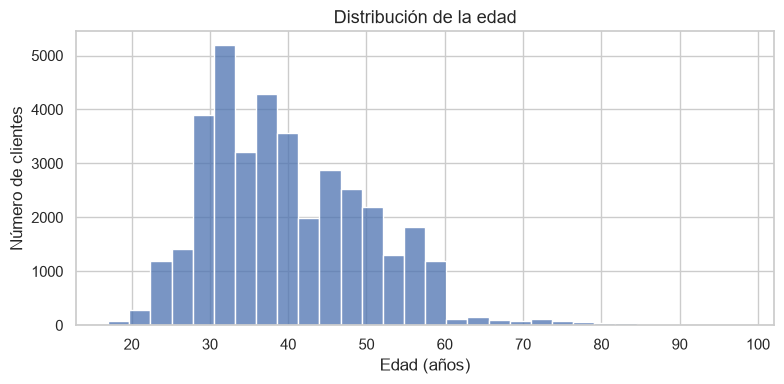

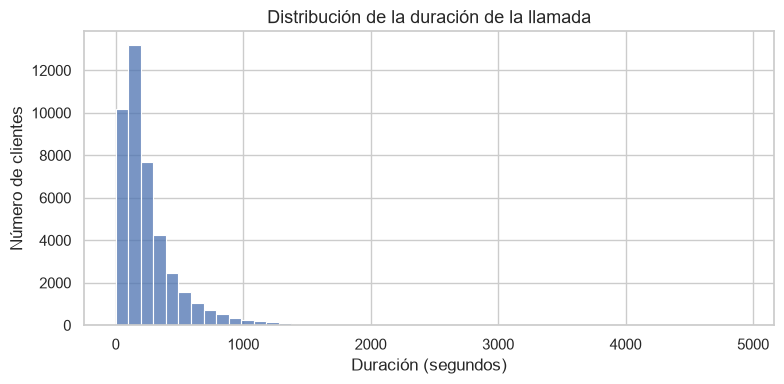

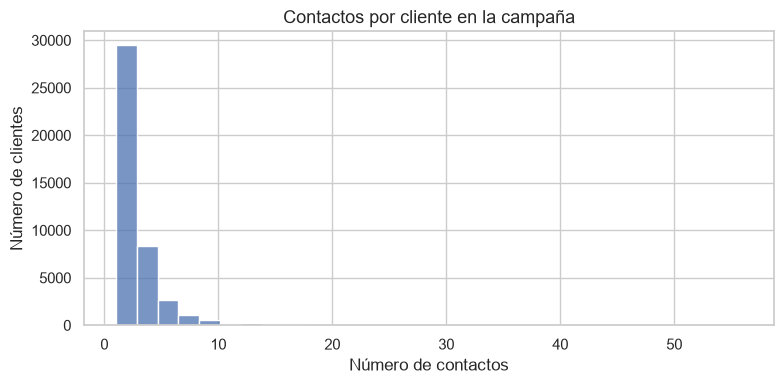

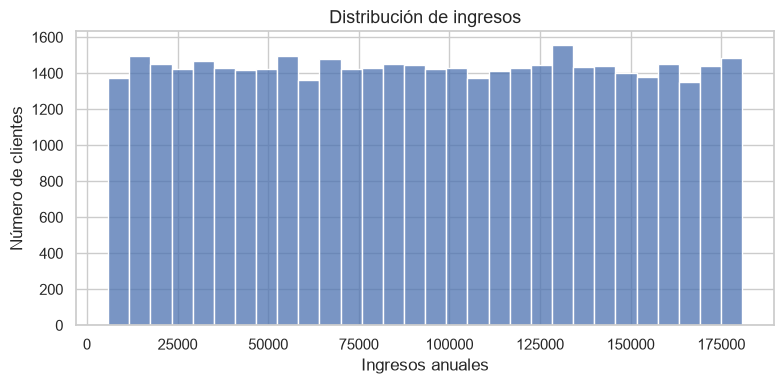

In [37]:
histograma(df, "edad", "Distribución de la edad", "Edad (años)", bins=30)
histograma(df, "duracion", "Distribución de la duración de la llamada", "Duración (segundos)", bins=50)
histograma(df, "contactos_campana", "Contactos por cliente en la campaña", "Número de contactos", bins=30)
histograma(df, "ingresos", "Distribución de ingresos", "Ingresos anuales", bins=30)

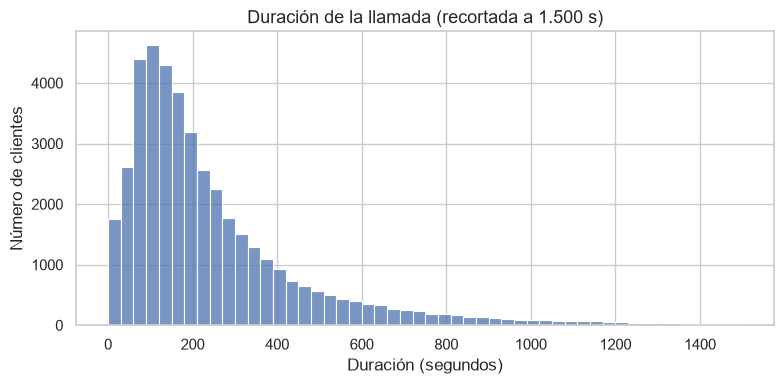

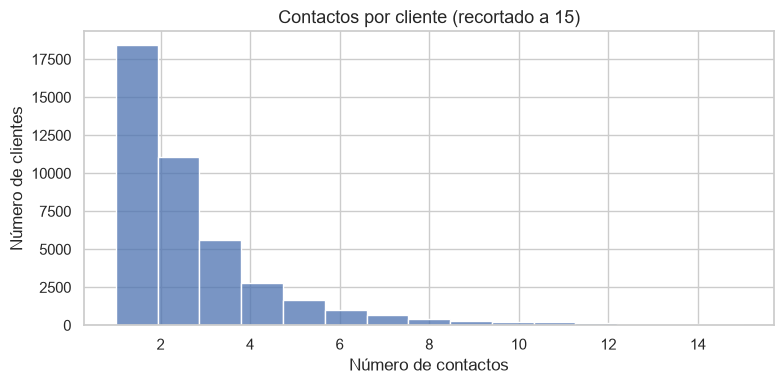

In [38]:
histograma(df[df["duracion"] <= 1500], "duracion", "Duración de la llamada (recortada a 1.500 s)", "Duración (segundos)", bins=50)
histograma(df[df["contactos_campana"] <= 15], "contactos_campana", "Contactos por cliente (recortado a 15)", "Número de contactos", bins=15)

In [39]:
(df["duracion"] > 1500).sum()

np.int64(211)

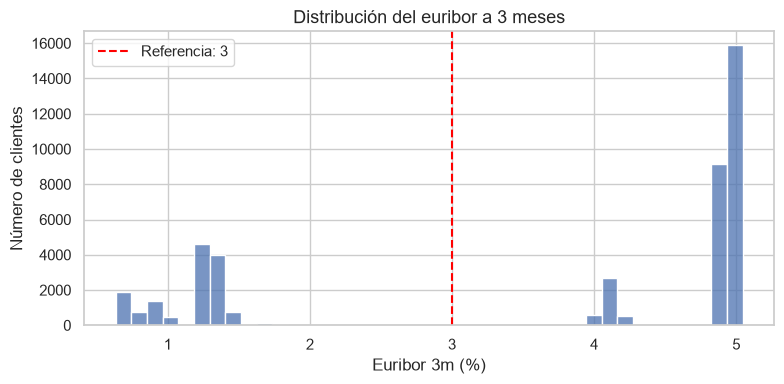

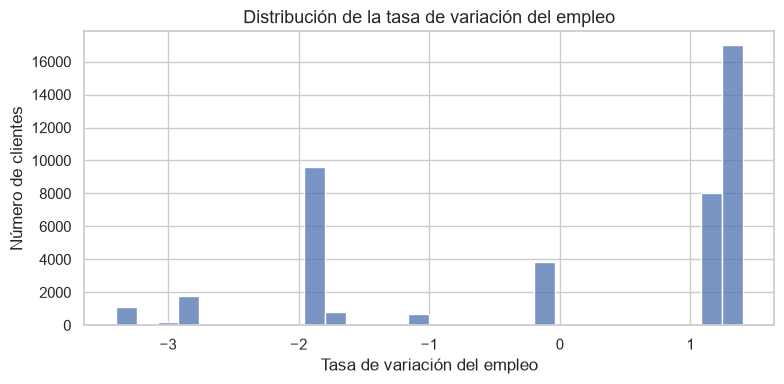

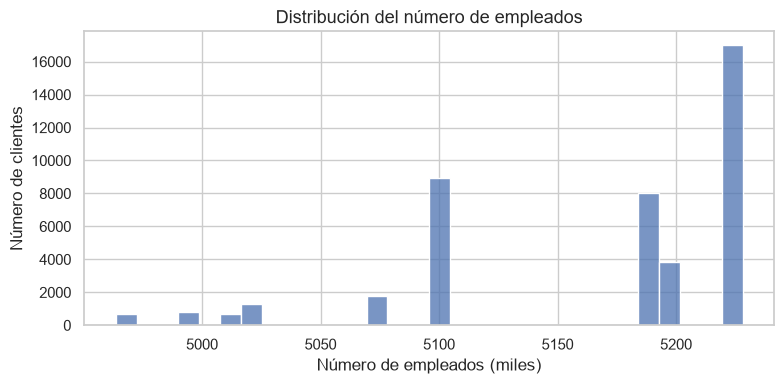

In [40]:
histograma(df, "euribor_3m", "Distribución del euribor a 3 meses", "Euribor 3m (%)", bins=40, linea=3)
histograma(df, "tasa_var_empleo", "Distribución de la tasa de variación del empleo", "Tasa de variación del empleo", bins=30)
histograma(df, "num_empleados", "Distribución del número de empleados", "Número de empleados (miles)", bins=30)

In [41]:
def barras_categoria(df, columna, titulo, orden=None):
    fig, ax = plt.subplots()
    sns.countplot(data=df, y=columna, order=orden, ax=ax, color="steelblue")
    ax.set_title(titulo)
    ax.set_xlabel("Número de clientes")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

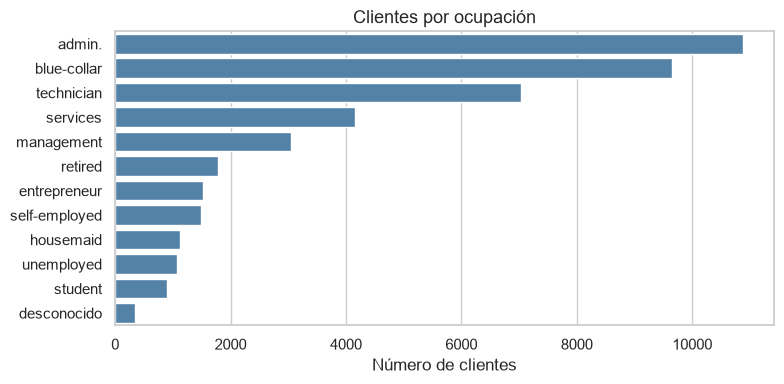

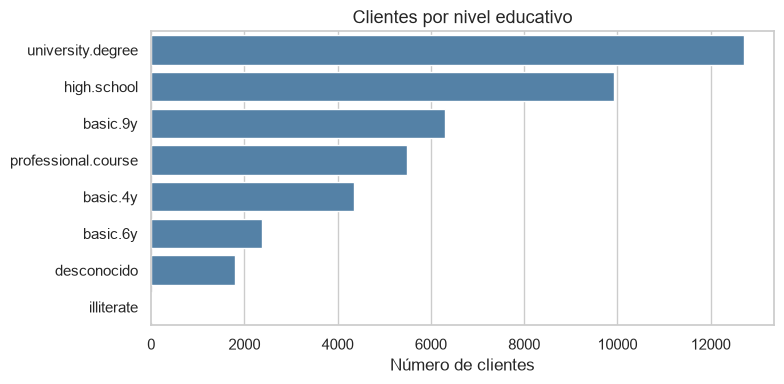

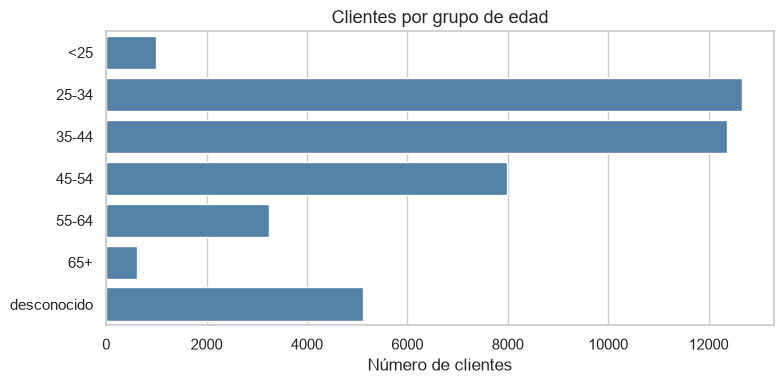

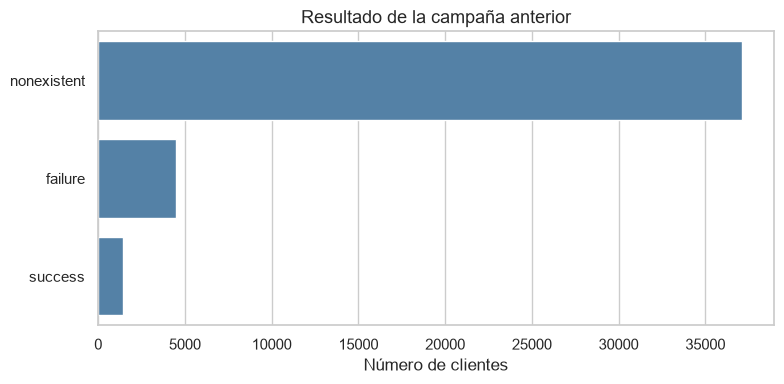

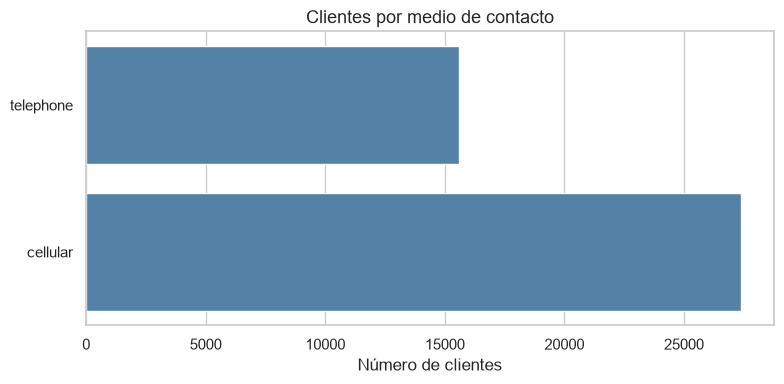

In [42]:
barras_categoria(df, "trabajo", "Clientes por ocupación", orden=df["trabajo"].value_counts().index)
barras_categoria(df, "educacion", "Clientes por nivel educativo", orden=df["educacion"].value_counts().index)
barras_categoria(df, "grupo_edad", "Clientes por grupo de edad")
barras_categoria(df, "resultado_previo", "Resultado de la campaña anterior", orden=df["resultado_previo"].value_counts().index)
barras_categoria(df, "medio_contacto", "Clientes por medio de contacto")

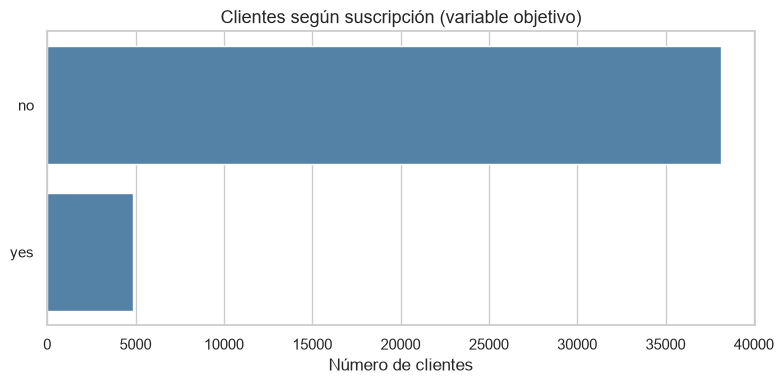

In [43]:
barras_categoria(df, "suscrito", "Clientes según suscripción (variable objetivo)")

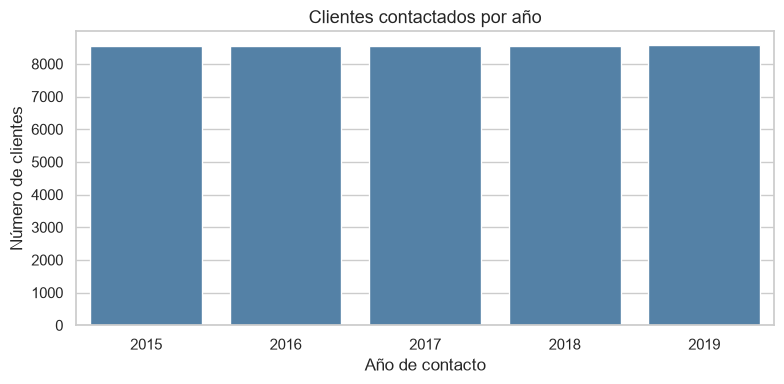

In [44]:
fig, ax = plt.subplots()
sns.countplot(data=df.dropna(subset=["anio_contacto"]), x="anio_contacto", ax=ax, color="steelblue")
ax.set_title("Clientes contactados por año")
ax.set_xlabel("Año de contacto")
ax.set_ylabel("Número de clientes")
plt.tight_layout()
plt.show()

## Interpretación de las distribuciones (provisional - falta completar)

**Variables numéricas**
- `edad`: [forma]. Faltan 5.120 valores.
- `duracion`: cola larga a la derecha; X clientes superan los 1.500 s.
- `contactos_campana`: cola larga a la derecha; X clientes superan los 15 contactos.
- `ingresos`: distribución [plana / casi uniforme], coherente con un origen sintético.

**Contexto económico**
- `euribor_3m`: [dos bloques / otra forma]. El corte en 3 [queda justificado / no].
- `tasa_var_empleo` y `num_empleados`: [forma].

**Variables categóricas**
- `trabajo`: ...
- `resultado_previo`: 86,3 % `nonexistent`.
- `suscrito`: variable objetivo desbalanceada.

**Temporal**
- Los contactos se reparten de forma casi idéntica entre 2015 y 2019 (≈ 8.550 por año).

In [45]:
print((df["duracion"] > 1500).sum(), (df["contactos_campana"] > 15).sum())

211 372


## Interpretación de las distribuciones

**Variables numéricas**
- `edad`: distribución asimétrica, con el grueso entre los 28 y los 40 años y cola hacia edades altas; cae bruscamente a partir de los 60. Faltan 5.120 valores.
- `duracion`: cola larga a la derecha (hasta casi 5.000 s). En la vista recortada hay un pico en torno a 100-150 s. [X] clientes superan los 1.500 s y quedan fuera de esa vista (no se eliminan del dataset).
- `contactos_campana`: la mayoría recibe 1 o 2 contactos; cola hasta 56. [X] clientes superan los 15 contactos.
- `ingresos`: distribución plana (de unos 6.000 a 180.000), coherente con un origen sintético.

**Contexto económico**
- `euribor_3m`: dos bloques separados, uno bajo (≈ 0,6-1,7) y otro alto (≈ 4-5), sin valores entre 2 y 4. El corte en 3 queda dentro de ese hueco. El pico alto cercano a 5 puede estar reforzado por la imputación por mediana.
- `tasa_var_empleo` y `num_empleados`: pocos valores repetidos muchas veces, porque describen el momento de la llamada y no al cliente.

**Variables categóricas**
- `trabajo`: `admin.`, `blue-collar` y `technician` concentran el 64 % de los clientes.
- `educacion`: dominan los universitarios y secundarios; `illiterate` (18 casos) es casi invisible.
- `resultado_previo`: 86,3 % `nonexistent`.
- `medio_contacto`: 63,7 % móvil.

**Temporal**
- [Completar con el gráfico por año: ≈ 8.550 clientes por año.]

**Variable objetivo**
- `suscrito`: desbalanceada, 88,7 % `no` frente a 11,3 % `yes` (4.844 clientes).

**Temporal**
- Los contactos se reparten de forma casi idéntica entre 2015 y 2019 (≈ 8.550 por año). Esta uniformidad es poco habitual y es coherente con fechas de contacto asignadas artificialmente.

- `duracion`: ... 211 clientes (0,5 %) superan los 1.500 s y quedan fuera de la vista recortada (no se eliminan del dataset).
- `contactos_campana`: ... 372 clientes (0,9 %) superan los 15 contactos y quedan fuera de la vista recortada.

## Sesión 11: gráficos de variables frente a suscripción

In [46]:
def grafico_tasa(df, columna, titulo, orden=None, min_clientes=500):
    tabla = tasa_por_segmento(df, columna)
    tabla = tabla[tabla["clientes"] >= min_clientes]   # quitamos segmentos con muestra pequeña

    if orden is not None:
        tabla = tabla.reindex([o for o in orden if o in tabla.index])
    else:
        tabla = tabla.sort_values("tasa_%", ascending=False)

    fig, ax = plt.subplots()
    sns.barplot(x=tabla["tasa_%"], y=tabla.index.astype(str), ax=ax, color="steelblue")
    ax.axvline(tasa_global, color="red", linestyle="--", label=f"Tasa global ({tasa_global:.1f} %)")

    # Etiqueta con la tasa y el nº de clientes al final de cada barra
    for i, (tasa, n) in enumerate(zip(tabla["tasa_%"], tabla["clientes"])):
        ax.text(tasa + 0.5, i, f"{tasa:.1f} % (n={n:,})".replace(",", "."), va="center", fontsize=9)

    ax.set_title(titulo)
    ax.set_xlabel("Tasa de suscripción (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, tabla["tasa_%"].max() * 1.3)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

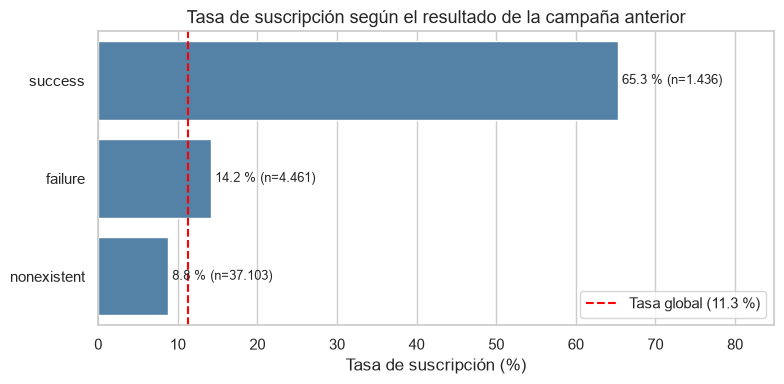

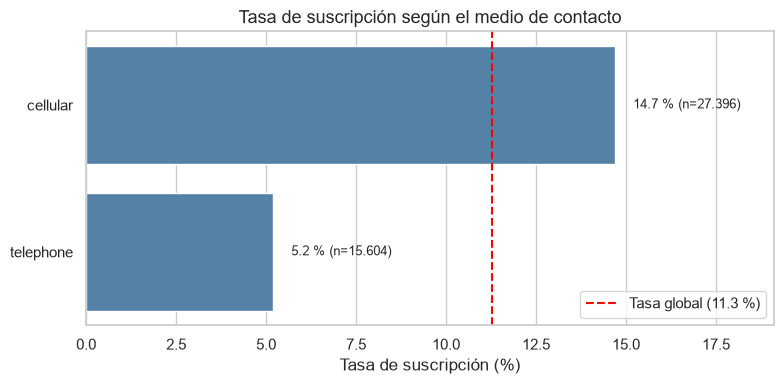

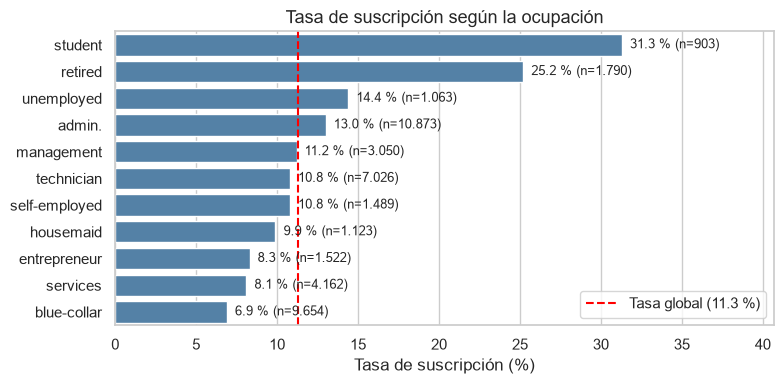

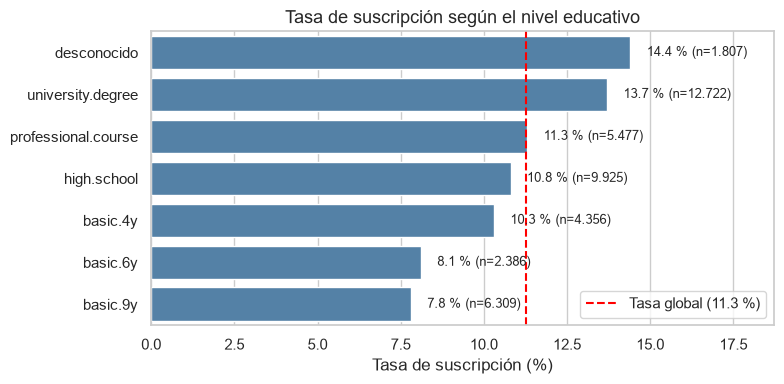

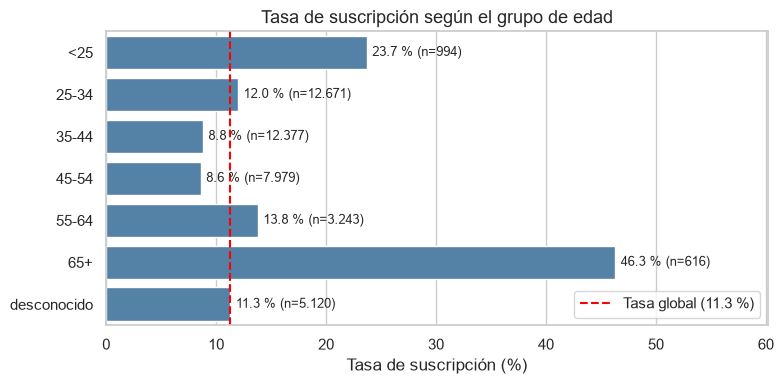

In [47]:
grafico_tasa(df, "resultado_previo", "Tasa de suscripción según el resultado de la campaña anterior")
grafico_tasa(df, "medio_contacto", "Tasa de suscripción según el medio de contacto")
grafico_tasa(df, "trabajo", "Tasa de suscripción según la ocupación")
grafico_tasa(df, "educacion", "Tasa de suscripción según el nivel educativo")
grafico_tasa(df, "grupo_edad", "Tasa de suscripción según el grupo de edad", orden=orden_edad)

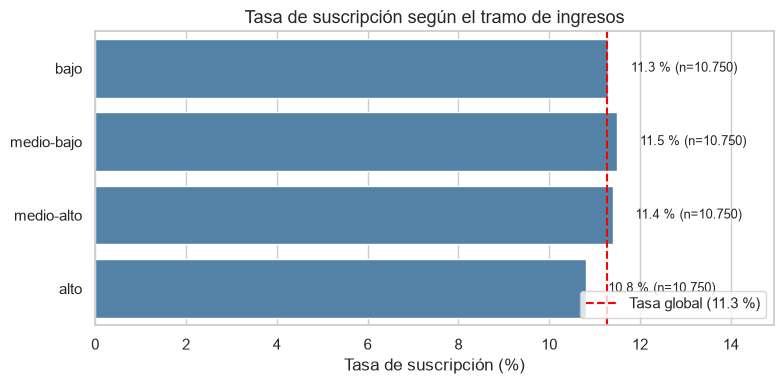

In [48]:
grafico_tasa(df, "tramo_ingresos", "Tasa de suscripción según el tramo de ingresos", orden=orden_ingresos)

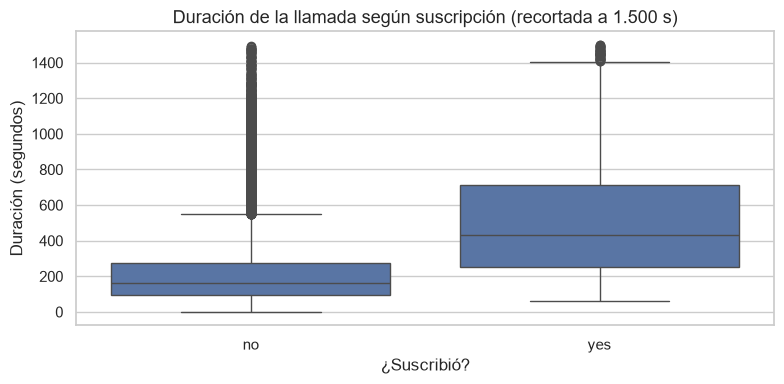

In [49]:
fig, ax = plt.subplots()
sns.boxplot(data=df[df["duracion"] <= 1500], x="suscrito", y="duracion", order=["no", "yes"], ax=ax)
ax.set_title("Duración de la llamada según suscripción (recortada a 1.500 s)")
ax.set_xlabel("¿Suscribió?")
ax.set_ylabel("Duración (segundos)")
plt.tight_layout()
plt.show()

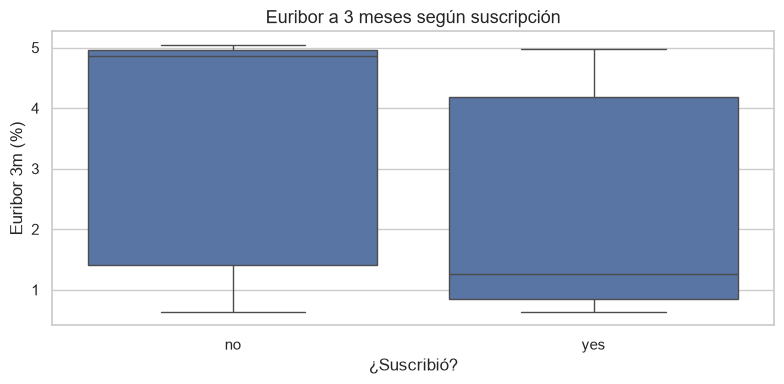

In [50]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="suscrito", y="euribor_3m", order=["no", "yes"], ax=ax)
ax.set_title("Euribor a 3 meses según suscripción")
ax.set_xlabel("¿Suscribió?")
ax.set_ylabel("Euribor 3m (%)")
plt.tight_layout()
plt.show()

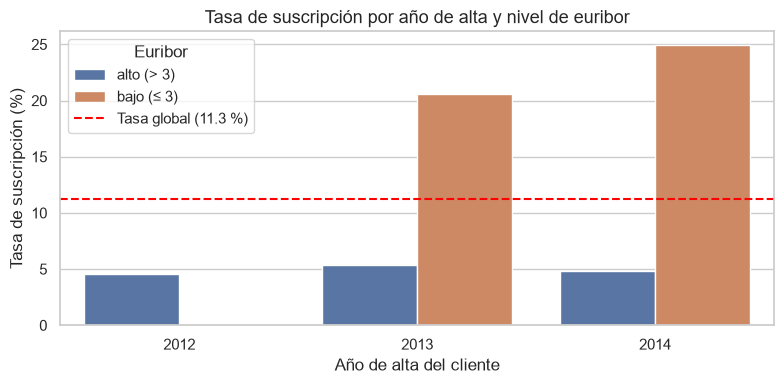

In [51]:
df["euribor_alto"] = np.where(df["euribor_3m"] > 3, "alto (> 3)", "bajo (≤ 3)")

tabla_euribor = (
    df.groupby(["anio_alta", "euribor_alto"])["suscrito_num"]
    .agg(clientes="count", tasa="mean")
    .reset_index()
)
tabla_euribor["tasa_%"] = (tabla_euribor["tasa"] * 100).round(1)

fig, ax = plt.subplots()
sns.barplot(data=tabla_euribor, x="anio_alta", y="tasa_%", hue="euribor_alto", ax=ax)
ax.axhline(tasa_global, color="red", linestyle="--", label=f"Tasa global ({tasa_global:.1f} %)")
ax.set_title("Tasa de suscripción por año de alta y nivel de euribor")
ax.set_xlabel("Año de alta del cliente")
ax.set_ylabel("Tasa de suscripción (%)")
ax.legend(title="Euribor")
plt.tight_layout()
plt.show()

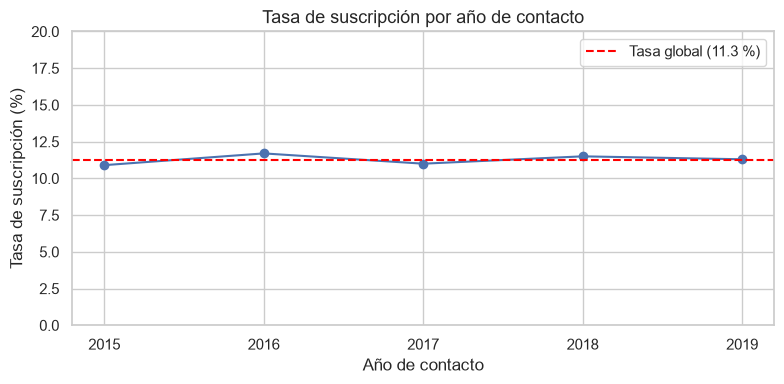

In [52]:
tasa_anio = tasa_por_segmento(df, "anio_contacto").sort_index()

fig, ax = plt.subplots()
ax.plot(tasa_anio.index.astype(str), tasa_anio["tasa_%"], marker="o")
ax.axhline(tasa_global, color="red", linestyle="--", label=f"Tasa global ({tasa_global:.1f} %)")
ax.set_ylim(0, 20)
ax.set_title("Tasa de suscripción por año de contacto")
ax.set_xlabel("Año de contacto")
ax.set_ylabel("Tasa de suscripción (%)")
ax.legend()
plt.tight_layout()
plt.show()

# Provisional

## Interpretación de los gráficos bivariantes

**Historial y canal**
- `resultado_previo`: los clientes con éxito previo suscriben el 65,3 %, frente al 14,2 % (fracaso) y 8,8 % (sin campaña previa).
- `medio_contacto`: móvil 14,7 % frente a fijo 5,2 %. Posible mezcla con el periodo.

**Perfil**
- `grupo_edad`: patrón en U, <25 años 23,7 % y 65+ 46,3 % frente al 8,6-8,8 % de 35-54.
- `trabajo`: student 31,3 % y retired 25,2 % arriba; blue-collar 6,9 % abajo. Va ligado a la edad.
- `tramo_ingresos`: tasas entre 10,8 % y 11,5 %, sin efecto apreciable.

**Llamada y contexto económico**
- `duracion`: mediana 449 s en suscritos frente a 163 s. Correlación, no causa.
- `euribor_3m`: mediana 1,27 en suscritos frente a 4,86.
- Euribor y año de alta: con euribor alto la tasa es ≈ 5 % en los tres años; con euribor bajo, 20,6-24,9 %. El año de alta deja de marcar diferencias.

**Temporal**
- Por año de contacto la tasa es casi plana (10,9-11,7 %).

## Interpretación de los gráficos bivariantes

**Historial y canal**
- `resultado_previo`: los clientes con éxito previo suscriben el 65,3 % (n=1.436), frente al 14,2 % tras un fracaso y el 8,8 % sin campaña previa.
- `medio_contacto`: móvil 14,7 % frente a fijo 5,2 %. Posible mezcla con el periodo de contacto.

**Perfil**
- `grupo_edad`: patrón en U. <25 años 23,7 % y 65+ años 46,3 %, frente al 8,6-8,8 % de 35-54. Los clientes sin edad (11,3 %) coinciden con la media.
- `trabajo`: `student` (31,3 %) y `retired` (25,2 %) arriba; `blue-collar` (6,9 %) abajo. Está ligado a la edad, no es un hallazgo independiente.
- `educacion`: diferencias moderadas (de 7,8 % en `basic.9y` a 13,7 % en `university.degree`).
- `tramo_ingresos`: tasas entre 10,8 % y 11,5 %, sin efecto apreciable.

**Llamada y contexto económico**
- `duracion`: los suscritos tienen llamadas bastante más largas (mediana 449 s frente a 163 s). Es una correlación, no una causa: la duración se conoce al final de la llamada.
- `euribor_3m`: mediana de 1,27 en suscritos frente a 4,86 en no suscritos.
- Euribor y año de alta: con euribor alto la tasa es ≈ 5 % en 2012, 2013 y 2014; con euribor bajo, 20,6 % (2013) y 24,9 % (2014). Al controlar por euribor, el año de alta deja de marcar diferencias. Ningún cliente de 2012 tiene euribor bajo.

**Temporal**
- Por año de contacto la tasa es casi plana (10,9-11,7 %), coherente con fechas de contacto asignadas de forma artificial.